# Exoplanet vetting with machine learning: onboarding

**What this is:** a guided tour of the project, so you can explain and defend it: what the data is, why vetting
matters, how the model is built and tested, what still goes wrong, and where it could go next. Every code cell is
light (a few seconds, nothing trains); results are read from saved files.

**The project in one sentence:** given the catalog numbers that NASA's Kepler pipeline measured for each
transit-like signal (a *Kepler Object of Interest*, KOI), predict whether it is a real planet or a false positive,
with an honest estimate of how well that works.

**Contents**
0. Setup
1. Why this matters
2. The data: transits, catalog features, labels
3. The machine-learning problem, and how it is kept honest
4. What is distinctive here: evaluation, input transforms, ensembling, operating points
5. Results
6. Kinks to work out (ranked)
7. Future work
8. Glossary

Detailed write-up: `sweeps/REPORT.md`. Dated working notebooks: `notebooks/`. Phase 2 plan: `PHASE2_PLAN.md`.

## 0. Setup
Loads the project code (`src/VettingSetup.jl`) and the cached Kepler cumulative KOI table (`data/`).

In [1]:
include(joinpath(@__DIR__, "src", "VettingSetup.jl"))
df_raw = load_koi()          # every column of the NASA Exoplanet Archive "cumulative" KOI table
df = clean_koi(df_raw)       # the 11 model features + label, rows with a known disposition
pool, test = cv_pool(df)     # pool = everything used for development; test = sealed hold-out (10% of stars)
@printf("raw KOIs %d | usable %d on %d stars | pool %d | sealed test %d\n",
        nrow(df_raw), nrow(df), length(unique(df.kepid)), nrow(pool), nrow(test))

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
raw KOIs 9564 | usable 9201 on 7927 stars | pool 8288 | sealed test 913


## 1. Why this matters

**The transit method.** When a planet crosses its star, it blocks a fraction of the light equal to the area ratio,
$\delta \approx (R_p/R_\star)^2$. Earth crossing the Sun is a dip of about 84 ppm (0.008%) lasting ~13 hours once a
year. Jupiter is a ~1% dip. Kepler (launched March 2009) stared at ~150,000 stars in Cygnus–Lyra for four years,
with a measurement every 30 minutes, to find exactly these dips.

**The problem: many dips are not planets.** The automated search produces thousands of periodic signals. Many are:
- **eclipsing binaries (EBs):** two stars eclipsing each other, deep and often V-shaped, usually with a secondary
  eclipse;
- **background eclipsing binaries:** a faint EB behind or near the target, whose deep eclipse is *diluted* by the
  bright target star into a small, planet-like dip;
- **contamination:** light from a bright variable star leaking onto the target's pixels;
- **instrumental artifacts and stellar variability.**

Deciding which signals are real planets is called **vetting**. For Kepler it was done by the *Robovetter*, a
hand-built decision tree of tests (DR25 catalog, Thompson et al. 2018), plus human review and follow-up observations.

**Who uses vetting results, and why it matters:**
- **Follow-up programmes.** Confirming a planet takes scarce telescope time: radial-velocity spectrographs, high-
  resolution imaging. A good vetter decides which candidates are worth it.
- **Planet demographics.** "How common are Earth-like planets?" ($\eta_\oplus$) needs a catalog whose *reliability*
  (fraction of real planets) is known. That number drives target planning for future missions such as NASA's
  Habitable Worlds Observatory.
- **Current and future surveys.** TESS (since 2018) has produced thousands of candidates; ESA's PLATO and NASA's
  Roman will produce many more. Human vetting does not scale, so ML vetters are an active research area (Google's
  AstroNet found Kepler-90i in 2017; NASA's ExoMiner validated 301 new Kepler planets in 2021).

**Who hires for this skill:** exoplanet and survey science teams (NASA Ames, NASA Exoplanet Science Institute/IPAC,
STScI/MAST, TESS and PLATO science teams), and more broadly any national-lab or space-science group that
classifies noisy signals with ML. The transferable skill is less the network itself than **honest evaluation of a
classifier on messy scientific data**: leakage control, uncertainty on every number, and a frank account of failure
modes.

## 2. The data
### 2.1 The transit signal and what fakes it
Three textbook relations do most of the work:
- **Depth:** $\delta \approx (R_p/R_\star)^2$. A planet larger than ~2 Jupiter radii (depth ≳ 4% around a Sun-like
  star) is physically implausible, so very deep dips are almost always stellar eclipses.
- **Kepler's third law:** $a^3 = G M_\star P^2 / 4\pi^2$. Period plus stellar mass gives the orbit size $a$.
- **Duration:** for a central transit, $T_0 \approx \frac{P}{\pi}\frac{R_\star}{a}$, and
  $T \approx T_0\sqrt{1-b^2}$ for impact parameter $b$. A planet's duration must be consistent with its star. A
  duration far from this is a red flag (wrong star, i.e. a background source, or not a transit at all).

Toy light curves (made up, not data) for the three classic cases:

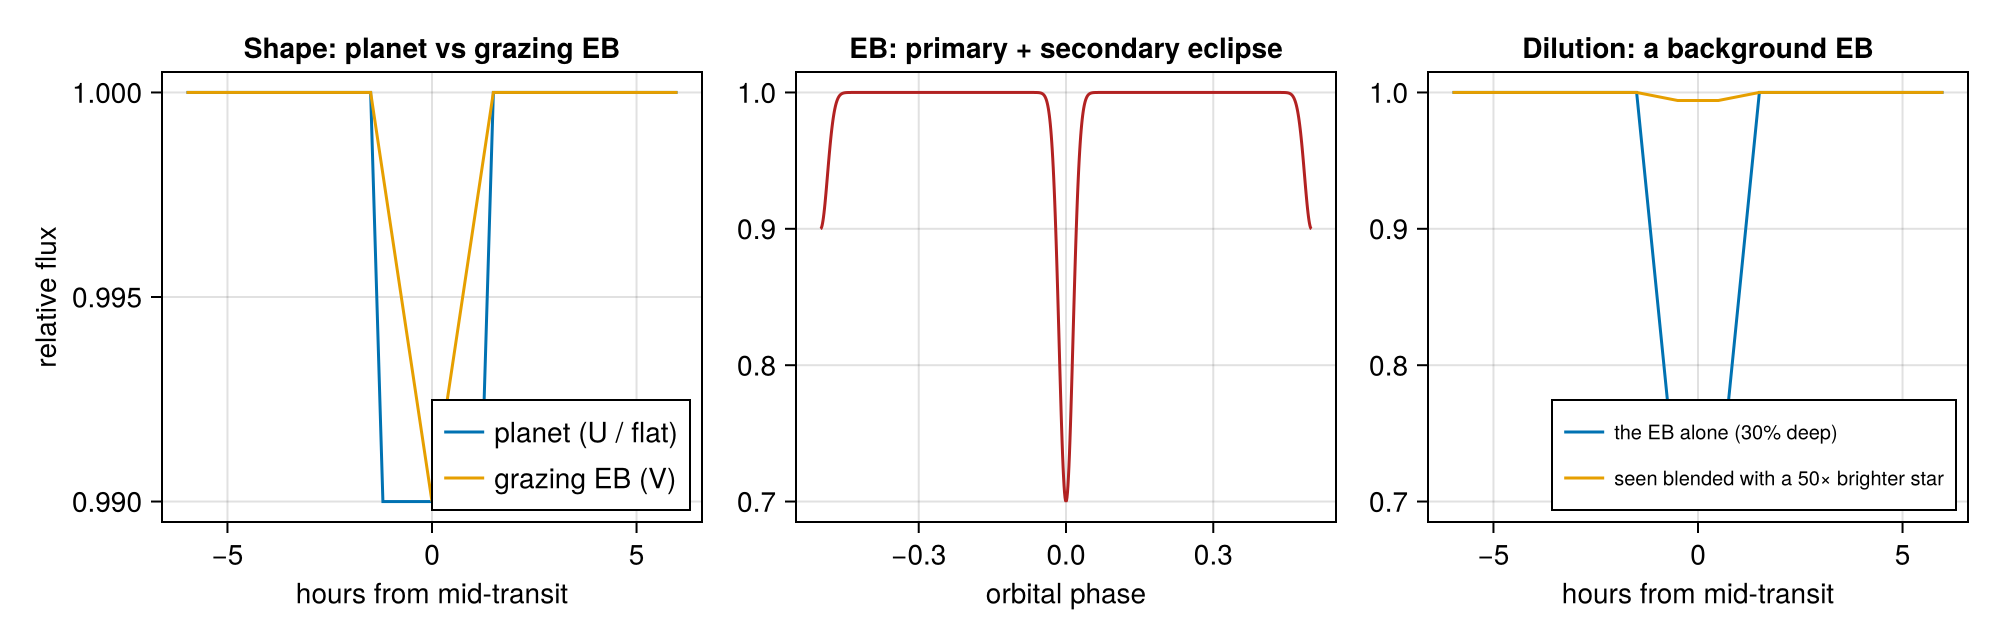

In [2]:
t = range(-6, 6; length = 601)                                    # hours from mid-transit
trap(t; depth, T, tin) = 1 .- depth .* clamp.((T / 2 .- abs.(t)) ./ tin, 0, 1)   # trapezoid transit
planet = trap(t; depth = 0.01, T = 3.0, tin = 0.3)              # flat bottom, short ingress/egress
grazing = trap(t; depth = 0.01, T = 3.0, tin = 1.5)             # V-shaped: grazing eclipsing binary
ph = range(-0.5, 0.5; length = 1001)                              # orbital phase
eb = 1 .- 0.3 .* exp.(-(ph ./ 0.02) .^ 2) .- 0.1 .* exp.(-((abs.(ph) .- 0.5) ./ 0.02) .^ 2)
fig = Figure(size = (1000, 320))
ax = Axis(fig[1, 1]; xlabel = "hours from mid-transit", ylabel = "relative flux", title = "Shape: planet vs grazing EB")
lines!(ax, t, planet; label = "planet (U / flat)"); lines!(ax, t, grazing; label = "grazing EB (V)")
axislegend(ax; position = :rb)
ax = Axis(fig[1, 2]; xlabel = "orbital phase", title = "EB: primary + secondary eclipse")
lines!(ax, ph, eb; color = :firebrick)
ax = Axis(fig[1, 3]; xlabel = "hours from mid-transit", title = "Dilution: a background EB")
lines!(ax, t, trap(t; depth = 0.30, T = 3.0, tin = 1.0); label = "the EB alone (30% deep)")
lines!(ax, t, 1 .- (1 .- trap(t; depth = 0.30, T = 3.0, tin = 1.0)) ./ 51;
       label = "seen blended with a 50× brighter star")
axislegend(ax; position = :rb, labelsize = 10)
fig

The third panel is why background EBs are hard: dilution by a factor of $F_\star/(F_\star+F_{bg})$ turns a 30% eclipse
into a 0.6% dip that looks like a Jupiter. The tell-tales are subtle: a V-shape, and the light centroid shifting
towards the faint star during the dip (the **centroid offset** test).

### 2.2 Do real KOIs obey the physics? Two checks on the catalog
**Depth.** Real planets cluster below ~1–2% depth. False positives extend to tens of percent (stellar eclipses).

CONFIRMED       median ratio 0.90;  ratio > 1.5 for 2.3%
FALSE POSITIVE  median ratio 1.10;  ratio > 1.5 for 32.5%


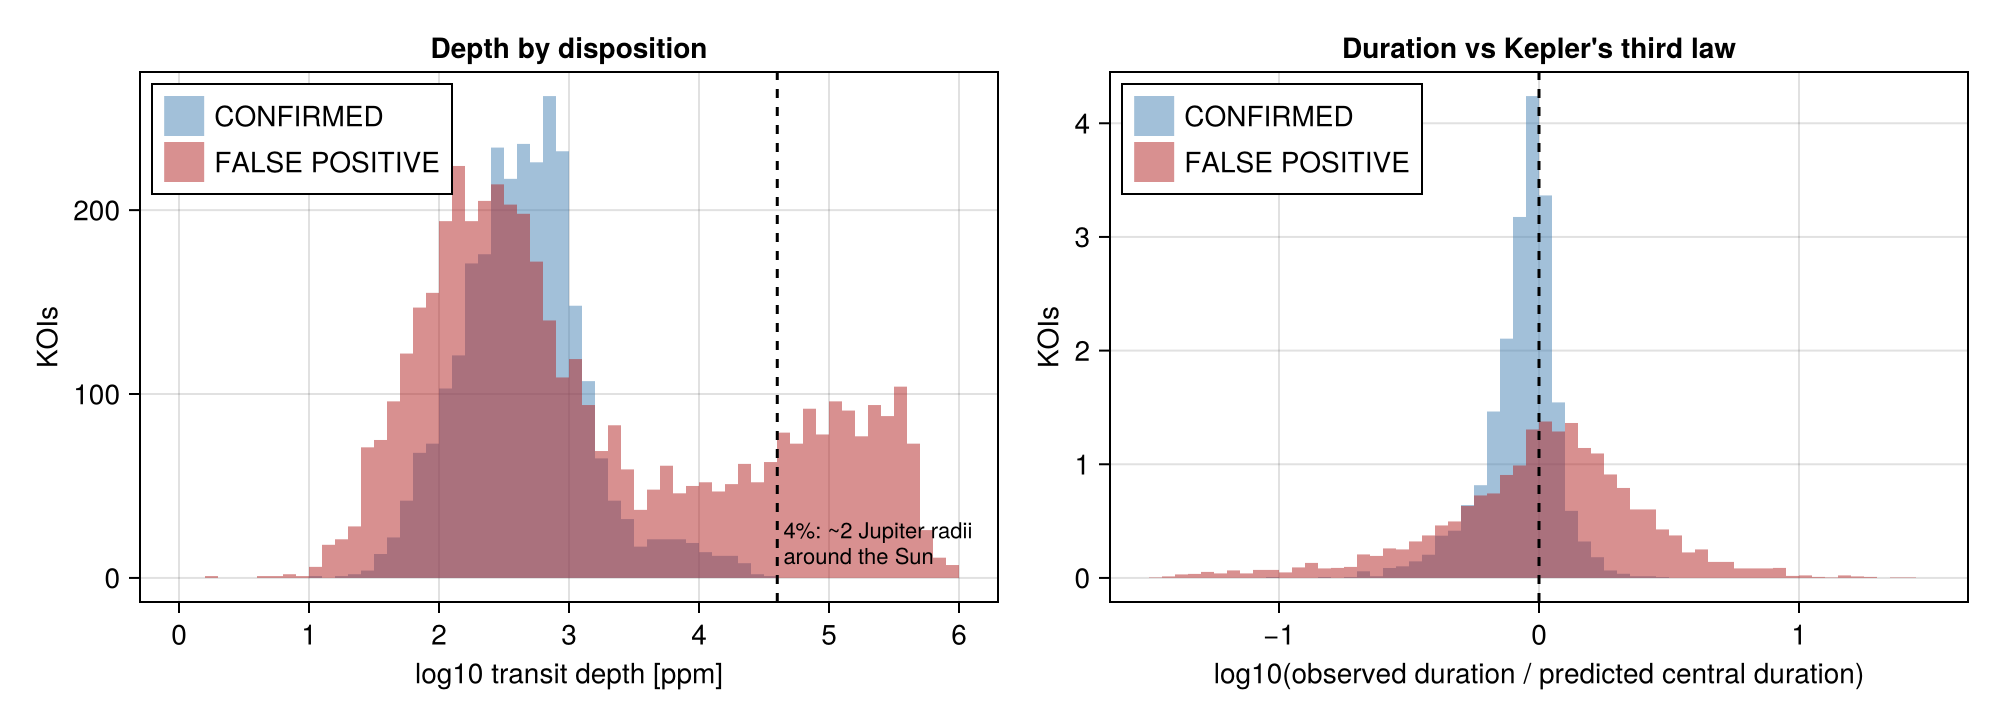

In [3]:
fig = Figure(size = (1000, 360))
ax = Axis(fig[1, 1]; xlabel = "log10 transit depth [ppm]", ylabel = "KOIs", title = "Depth by disposition")
for (d, col) in (("CONFIRMED", :steelblue), ("FALSE POSITIVE", :firebrick))
    v = df.koi_depth[(df.koi_disposition .== d) .& (df.koi_depth .> 0)]
    hist!(ax, log10.(v); bins = 0:0.1:6, color = (col, 0.5), label = d)
end
vlines!(ax, [log10(0.04e6)]; color = :black, linestyle = :dash)
text!(ax, log10(0.04e6), 5; text = " 4%: ~2 Jupiter radii\n around the Sun", fontsize = 11)
axislegend(ax; position = :lt)
# Duration check: observed duration / central-transit duration predicted by Kepler's third law
r = dropmissing(df_raw[:, [:koi_disposition, :koi_period, :koi_duration, :koi_srad, :koi_smass]])
a_AU = (r.koi_smass .* (r.koi_period ./ 365.25) .^ 2) .^ (1 / 3)
T0_hr = r.koi_period .* 24 ./ π .* (r.koi_srad .* 0.00465047 ./ a_AU)       # R_sun in AU = 0.00465
ratio = r.koi_duration ./ T0_hr
ax = Axis(fig[1, 2]; xlabel = "log10(observed duration / predicted central duration)", ylabel = "KOIs",
          title = "Duration vs Kepler's third law")
for (d, col) in (("CONFIRMED", :steelblue), ("FALSE POSITIVE", :firebrick))
    v = ratio[(r.koi_disposition .== d) .& isfinite.(ratio) .& (ratio .> 0)]
    hist!(ax, log10.(v); bins = -1.5:0.05:1.5, color = (col, 0.5), label = d, normalization = :pdf)
    @printf("%-15s median ratio %.2f;  ratio > 1.5 for %.1f%%\n", d, median(v), 100 * mean(v .> 1.5))
end
vlines!(ax, [0.0]; color = :black, linestyle = :dash)
axislegend(ax; position = :lt)
fig

Confirmed planets pile up just below a ratio of 1. A non-central transit ($b>0$) is shorter, so ratios below 1 are
expected. False positives scatter much more widely: the signal often isn't from that star, or isn't a transit.
The model never sees this ratio directly, but it sees period, duration, stellar radius and log g, so it can learn
the same consistency check.

**A real astrophysical feature hiding in the data:** the *radius valley* (Fulton et al. 2017). Few planets lie between
~1.5 and 2 Earth radii. They are thought to be rocky cores whose atmospheres were stripped, versus planets that kept
them.

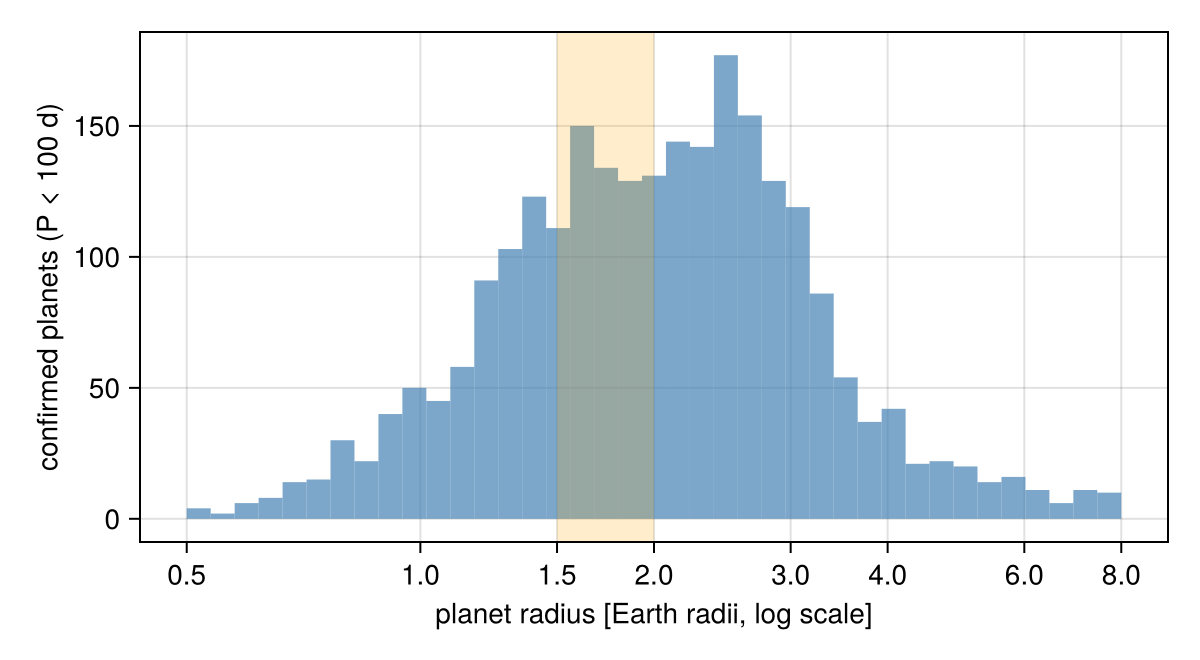

In [4]:
c = (df.koi_disposition .== "CONFIRMED") .& (df.koi_period .< 100) .& (0.5 .< df.koi_prad .< 8)
fig = Figure(size = (600, 330))
ax = Axis(fig[1, 1]; xlabel = "planet radius [Earth radii, log scale]", ylabel = "confirmed planets (P < 100 d)",
          xscale = log10, xticks = [0.5, 1, 1.5, 2, 3, 4, 6, 8])
hist!(ax, df.koi_prad[c]; bins = exp10.(range(log10(0.5), log10(8); length = 40)), color = (:steelblue, 0.7))
vspan!(ax, [1.5], [2.0]; color = (:orange, 0.2))
fig

### 2.3 The 11 catalog features the model uses

| Feature | Unit | Physical meaning | Why it helps |
|---|---|---|---|
| `koi_period` | days | Orbital period | EBs at short periods; artifacts at specific periods |
| `koi_duration` | hours | Transit duration | Must match the star (Kepler's third law) |
| `koi_depth` | ppm | Fraction of light blocked | Very deep means stellar eclipse |
| `koi_impact` | — | Impact parameter $b$ (0 = central, >1 = grazing) | Grazing fits are typical of EBs |
| `koi_model_snr` | — | Signal-to-noise of the fitted transit | Low-SNR signals are often noise |
| `koi_prad` | Earth radii | Planet radius from depth and stellar radius | Radii beyond ~2 $R_J$ are not planets |
| `koi_teq` | K | Equilibrium temperature (from flux received) | Encodes orbit + star |
| `koi_steff` | K | Stellar effective temperature | Star type |
| `koi_srad` | Solar radii | Stellar radius | Giants make radius estimates unreliable |
| `koi_slogg` | cgs | Stellar surface gravity | Dwarf vs giant |
| `koi_count` | — | Number of KOIs on the same star | Multi-planet systems are rarely false positives |

**Excluded on purpose (leakage):** the Robovetter's FP flags, `koi_score`, the dispositions, `kepler_name`, vetting
comments and dates. They *are* the answer, or are derived from it. `check_no_leakage()` throws an error if any of
them is requested as a feature.

**The multiplicity prior (`koi_count`)** is a strong prior (dropping it costs ~0.004 AUC), with a physical reason: it's
improbable for two independent false positives to land on the same star, so multi-KOI systems are mostly real.

In [5]:
combine(groupby(df, :koi_count), nrow => :kois, :label => (l -> round(mean(l); digits = 3)) => :planet_fraction)

Row,koi_count,kois,planet_fraction
,Int64,Int64,Float64
1,1,6993,0.387
2,2,1262,0.8
3,3,525,0.964
4,4,264,0.947
5,5,125,0.928
6,6,18,0.944
7,7,14,0.929


### 2.4 Labels, and how noisy they are
- **CONFIRMED:** verified planet (radial velocities, transit-timing variations, or statistical validation).
- **CANDIDATE:** passed vetting, not yet confirmed. **Counted as planet** here (the vetting question is "worth
  following up?"). Some are surely false positives: this is the noisiest label.
- **FALSE POSITIVE**, with up to four Robovetter flags (analysis only, never inputs):
  - **NT**, not transit-like: artifacts, variability, a non-transit shape.
  - **SS**, stellar eclipse: secondary eclipse, V-shape or too deep, i.e. an EB.
  - **CO**, centroid offset: the light centroid moves during the dip, so the source is a nearby star.
  - **EC**, ephemeris match: same period and epoch as another known object, i.e. contamination.

In [6]:
fpm = df_raw.koi_disposition .== "FALSE POSITIVE"
println("dispositions: ", sort(collect(countmap(df.koi_disposition)); by = last, rev = true))
for f in (:koi_fpflag_nt, :koi_fpflag_ss, :koi_fpflag_co, :koi_fpflag_ec)
    @printf("%-14s set on %4d of %d false positives\n", f, count(==(1), skipmissing(df_raw[fpm, f])), sum(fpm))
end

dispositions: Pair{DataStrings.DataString, Int64}["FALSE POSITIVE" => 4582, "CONFIRMED" => 2746, "CANDIDATE" => 1873]
koi_fpflag_nt  set on 1526 of 4839 false positives
koi_fpflag_ss  set on 2210 of 4839 false positives
koi_fpflag_co  set on 1889 of 4839 false positives
koi_fpflag_ec  set on 1148 of 4839 false positives


### 2.5 Two sub-populations: DR25 and supplemental KOIs
- **DR25 KOIs (~87%)** were found and vetted by the final, uniform Kepler pipeline (Q1–Q17 data, DR25 Robovetter).
  **Headline numbers are on these.**
- **Supplemental KOIs** come from earlier pipeline runs or other searches. Their catalog parameters are less uniform,
  and the model does much worse on them. They are always reported separately.
- **Rule:** whether a KOI is DR25 or supplemental (its *provenance*) is never a model input. A vetter for new data
  could not use it, and it correlates with the label for bookkeeping reasons.

**Centroid features (separate model):** `koi_dicco_*` / `koi_dikco_*` are the shift of the dip's position in
difference images, relative to the out-of-transit centroid or the catalog star position. `koi_fwm_*` is the
flux-weighted centroid motion. They target background EBs directly, but the Robovetter set its CO flag *by
thresholding these same numbers*. So a model using them partly re-learns that rule, which is why it's reported as a
separate "catalog + centroid" model, next to the independent "catalog-only" one.

## 3. The machine-learning problem, and how it is kept honest
**Task:** binary classification, planet (CONFIRMED + CANDIDATE) vs FALSE POSITIVE, from one row of catalog numbers.
**Output:** a planet probability per KOI.

**Leakage control, beyond excluding columns: split by star.** Several KOIs can sit on one star, and they share the
stellar features (and usually their label, through the multiplicity prior). If siblings landed in both training and
test, the model would be graded on a star it had already seen. So every split groups KOIs by star (`kepid`).

In [7]:
sys = star_systems(pool)
@printf("pool: %d KOIs on %d stars; %.1f%% of KOIs share their star with another KOI\n", nrow(pool),
        nrow(sys), 100 * mean(pool.koi_count .> 1))
@printf("system types: %s\n", sort(collect(countmap(sys.system))))
@printf("sealed test: %d KOIs on %d stars, no star in common with the pool: %s\n", nrow(test),
        length(unique(test.kepid)), isempty(intersect(Set(pool.kepid), Set(test.kepid))))

pool: 8288 KOIs on 7135 stars; 24.1% of KOIs share their star with another KOI
system types: ["fp" => 3959, "mixed" => 78, "planet" => 3098]
sealed test: 913 KOIs on 792 stars, no star in common with the pool: true


**The protocol, step by step:**
1. **Sealed test set.** 10% of stars (seed 42) set aside on day one, scored **once** at the very end (10/13/2026).
2. **Cross-validation (CV) on the pool.** 5-fold, star-grouped and label-balanced folds, repeated over 5 different
   fold shuffles × 10 training seeds: 250 models per configuration. Every pool KOI gets an *out-of-fold* (OOF) score
   from models that never saw its star.
3. **Noise floor first (step 1).** Before comparing anything, measure how much a metric moves when *nothing*
   changes. A single notebook-style run varies by ±0.007 AUC from the luck of the validation split; two CV runs of
   the same configuration differ by < 0.0005.
4. **Paired comparisons.** Two models are compared on *identical* folds, and the difference gets a 95% interval from
   a bootstrap over stars. A change counts only if that interval excludes 0.
5. **Preprocessing fitted on training data only** (scalers, rank transforms, medians for missing values), inside
   every fold.

**Choices you should be able to defend:**
- *Why CANDIDATE = planet?* The use case is triage for follow-up. A CONFIRMED-only model was tested (§5); it ranks
  CONFIRMED vs FP slightly better but does the actual task worse.
- *Why ROC-AUC as the main number?* It's threshold-free and equals the probability that a random planet scores above a
  random FP. Operating points (recall, precision) are reported separately.
- *Why 250 models per configuration?* Without it, differences of 0.005 AUC (the size of most real improvements here)
  are invisible under run-to-run noise.
- *Why the test set only once?* Every look at it is a chance to tune to it. CV makes all the decisions; the test set
  checks whether CV was honest.

## 4. What is distinctive here
### 4.1 ROC-AUC is a probability: a quick check
$\mathrm{AUC} = P(s_{\text{planet}} > s_{\text{FP}})$. The fast version uses ranks (the Mann–Whitney statistic):
$\mathrm{AUC} = \frac{\sum_{i \in \text{planets}} \text{rank}_i - n_1(n_1+1)/2}{n_1 n_0}$.
Below, a brute-force count over all planet–FP pairs agrees with it, using saved pool OOF scores (no test data).

In [8]:
oofb = CSV.read(joinpath(CV_DIR, "oof_baselines_r5s10.csv"), DataFrame)
sm = oofb[randperm(Xoshiro(1), nrow(oofb))[1:400], :]
s1, s0 = sm.tree_tuned[sm.label .== 1], sm.tree_tuned[sm.label .== 0]
brute = mean(a > b ? 1.0 : a == b ? 0.5 : 0.0 for a in s1, b in s0)
@printf("400 random pool KOIs: brute-force pair count %.4f  vs  rank formula %.4f\n", brute, fast_auc(sm.label, sm.tree_tuned))

400 random pool KOIs: brute-force pair count 0.9500  vs  rank formula 0.9500


### 4.2 Rank-gauss inputs: why the neural network caught up with the trees
Several features span orders of magnitude (SNR from ~7 to ~9,000). Z-scoring them leaves most KOIs squashed in a
tiny range, which is hard for a neural network (trees don't care, because they only use the order of values). The
fix maps each feature through its training-set empirical CDF and then the inverse normal CDF:
$z = \Phi^{-1}\!\left(\hat F_{\text{train}}(x)\right)$. Result: MLP 0.9265 → **0.9330** AUC, tying the
gradient-boosted trees.

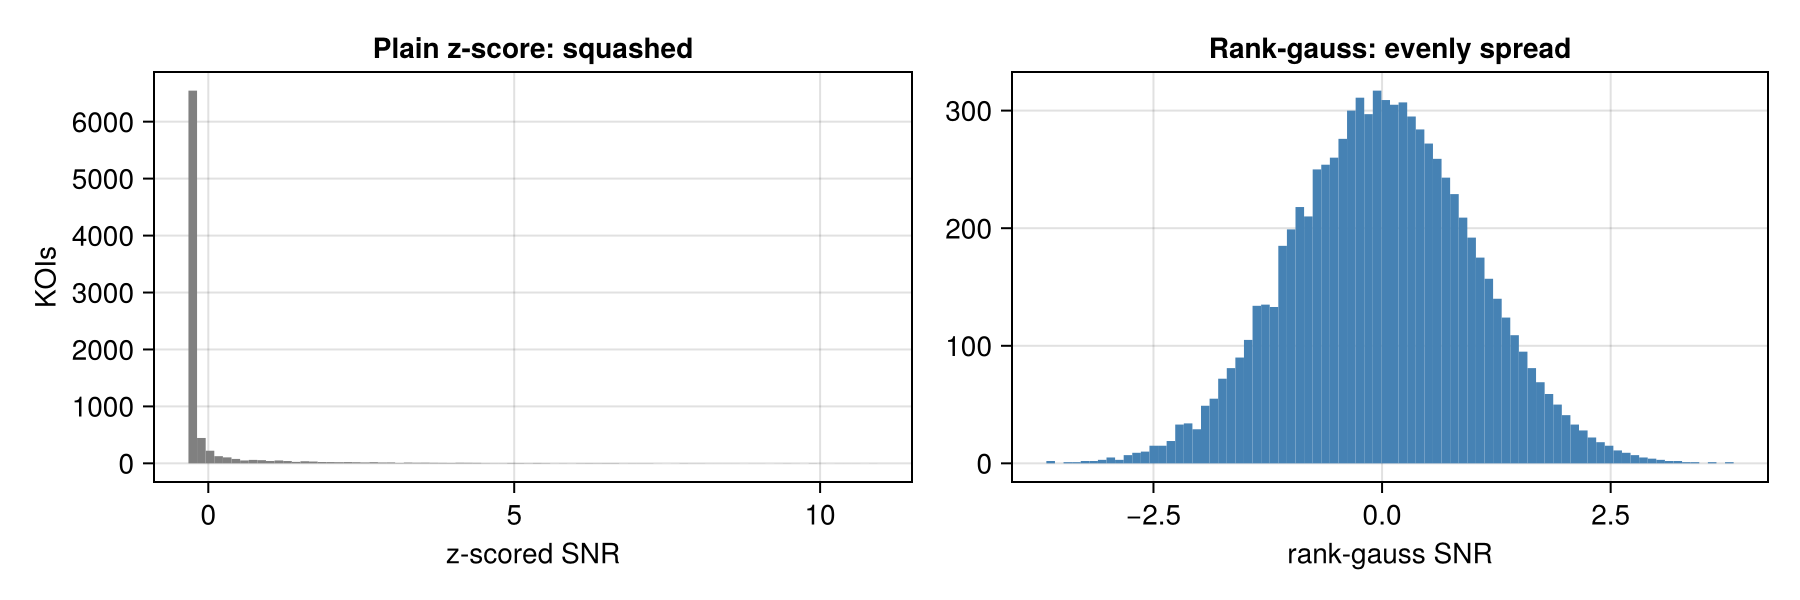

In [9]:
x = Float64.(pool.koi_model_snr)
q = vec(apply_quantile(fit_quantile(reshape(x, 1, :)), reshape(x, 1, :)))
fig = Figure(size = (900, 300))
ax = Axis(fig[1, 1]; xlabel = "z-scored SNR", ylabel = "KOIs", title = "Plain z-score: squashed")
hist!(ax, (x .- mean(x)) ./ std(x); bins = 80, color = :gray)
ax = Axis(fig[1, 2]; xlabel = "rank-gauss SNR", title = "Rank-gauss: evenly spread")
hist!(ax, q; bins = 80, color = :steelblue)
fig

### 4.3 Two different models, averaged
The final model is a 50/50 average of a **quantile-input MLP** (64-32 hidden units, dropout, early stopping) and
**gradient-boosted trees** (EvoTrees, depth 8, early stopping). Each is a 10-seed ensemble. They make partly
different mistakes, and the average beat both: 0.9352 vs 0.9330 / 0.9320 (pooled CV, all KOIs; a real gain by the
paired test).

### 4.4 Calibration and operating points
- **Calibration:** "0.8" should mean "80% of such KOIs are planets". Checked with nested CV (calibrator fitted
  without the held-out fold). Both models were already calibrated on DR25 KOIs: a Platt fit
  $p' = \sigma(a\,\mathrm{logit}(p) + b)$ came out at $a \approx 1.04$, $b \approx -0.02$, essentially the identity.
  So no calibrator is used.
- **Operating points:** a threshold turns probabilities into decisions. Instead of one magic threshold, there's a
  **menu**: keep 95/98/99% of planets, reach 95/99% precision, best F1, or p = 0.5. Each threshold is chosen without
  the fold it's scored on.
- **The headline is 98% planet recall** (your decision): the vetter is a triage filter, and a rejected planet is lost
  while a false positive only costs follow-up time.

In [10]:
menu = CSV.read(joinpath(CV_DIR, "step5_operating_points.csv"), DataFrame)
menu[:, [:model, :rule, :frozen_t, :dr25_recall, :dr25_precision, :dr25_fp_kept, :planets_lost_per1000, :fps_kept_per1000]]

Row,model,rule,frozen_t,dr25_recall,dr25_precision,dr25_fp_kept,planets_lost_per1000,fps_kept_per1000
,DataStri…,DataStri…,Float64,Float64,Float64,Float64,Int64,Int64
1,catalog-only,planet recall 95%,0.309,0.95,0.814,0.229,25,111
2,catalog-only,planet recall 98%,0.145,0.98,0.745,0.353,10,172
3,catalog-only,planet recall 99%,0.075,0.99,0.696,0.456,5,222
4,catalog-only,precision 95%,0.777,0.741,0.949,0.042,133,20
5,catalog-only,precision 99%,0.976,0.289,0.987,0.004,365,2
6,catalog-only,max F1,0.491,0.904,0.874,0.137,49,67
7,catalog-only,p = 0.5,0.5,0.9,0.881,0.129,52,63
8,catalog + centroid,planet recall 95%,0.442,0.95,0.913,0.096,26,47
9,catalog + centroid,planet recall 98%,0.211,0.98,0.856,0.173,10,84


## 5. Results
### 5.1 The progression (pooled CV ROC-AUC on DR25 KOIs)

| Model | DR25 ROC-AUC |
|---|---|
| Original MLP (10/09) | 0.948 |
| Tuned MLP + rank-gauss inputs | 0.953 |
| Gradient-boosted trees | 0.953 |
| **Catalog-only: MLP + trees average** | **0.955** |
| **Catalog + centroid** | **0.983** |
| Robovetter `koi_score` (reference, partly circular) | 0.970 |

### 5.2 The sealed test (scored once, 10/13/2026)
The frozen models on 913 never-seen KOIs (792 stars). "CV expected" is what cross-validation predicted.

In [11]:
CSV.read(joinpath(CV_DIR, "test_auc.csv"), DataFrame)

Row,model,subset,n,test_auc,test_ci,cv_expected
,DataStri…,DataStri…,Int64,Float64,DataStri…,Float64
1,catalog-only,DR25 KOIs (headline),796,0.9573,"[0.944, 0.970]",0.9542
2,catalog-only,DR25 CONFIRMED vs FP,661,0.9745,"[0.964, 0.983]",0.9776
3,catalog-only,supplemental KOIs,117,0.7242,"[0.634, 0.812]",0.6639
4,catalog-only,all KOIs,913,0.9413,"[0.927, 0.956]",0.9339
5,catalog + centroid,DR25 KOIs (headline),796,0.9883,"[0.982, 0.994]",0.9825
6,catalog + centroid,DR25 CONFIRMED vs FP,661,0.9954,"[0.991, 0.999]",0.9942
7,catalog + centroid,supplemental KOIs,117,0.7875,"[0.704, 0.864]",0.751
8,catalog + centroid,all KOIs,913,0.9786,"[0.971, 0.986]",0.9692
9,robovetter koi_score (reference),DR25 KOIs (headline),796,0.9794,—,NaN


In [12]:
tops = CSV.read(joinpath(CV_DIR, "test_operating_points.csv"), DataFrame)
tops[in.(tops.rule, Ref(["planet recall 98%", "max F1"])), [:model, :rule, :t, :recall, :cv_recall, :precision, :cv_precision, :fp_kept, :cv_fp_kept]]

Row,model,rule,t,recall,cv_recall,precision,cv_precision,fp_kept,cv_fp_kept
,DataStri…,DataStri…,Float64,DataStri…,Float64,DataStri…,Float64,Float64,Float64
1,catalog-only,planet recall 98%,0.145,"0.988 [0.975, 0.997]",0.98,"0.771 [0.731, 0.809]",0.745,0.305,0.353
2,catalog-only,max F1,0.491,"0.899 [0.868, 0.929]",0.904,"0.892 [0.861, 0.923]",0.874,0.113,0.137
3,catalog + centroid,planet recall 98%,0.211,"0.993 [0.983, 1.000]",0.98,"0.869 [0.837, 0.898]",0.856,0.156,0.173
4,catalog + centroid,max F1,0.548,"0.963 [0.943, 0.980]",0.93,"0.947 [0.920, 0.968]",0.937,0.056,0.066


**Reading it:**
- Test and CV agree: every CV estimate lies inside the test's 95% interval. That's the main evidence the protocol was
  honest.
- Catalog-only: **0.957** on DR25 KOIs. At the 98% planet-recall threshold, it keeps 31% of false positives.
- Catalog + centroid: **0.988**, keeping 16% of false positives at 98% recall. It even beats the Robovetter's own
  score (0.979), with the circularity caveat (§2.5).
- At the 98% threshold, no DR25 CONFIRMED planet in the test set was rejected by either model.

![Test ROC and reliability](figures/exo101326_test.png)

**The centroid features closed the biggest blind spot** (centroid-offset FPs missed: 36% → 4%):

![Centroid scores](figures/exo101326_centroid_scores.png)

**The post-test CONFIRMED-only experiment** (not adopted): it scores many CANDIDATEs as "unlike confirmed planets",
partly because confirmed planets are the *confirmable* ones.

![CONFIRMED-only](figures/exo101326_confirmed_only.png)

## 6. Kinks to work out (most important first)
1. **Supplemental KOIs** (AUC 0.67 catalog-only, 0.75 with centroids; probabilities miscalibrated). Their catalog
   numbers come from non-uniform pipelines. Fixing it without using provenance as an input needs better inputs, i.e.
   the light curves (Phase 2).
2. **"Not transit-like" and contamination false positives** (~25% still missed). Their give-aways are in the shape of
   the light curve or in other stars' ephemerides, neither of which is in the 11 features.
3. **Label noise in CANDIDATE.** Some candidates are false positives, and confirmed planets are a biased sample (high
   SNR, multi-planet systems). This caps the achievable score and colours what "planet-like" means.
4. **Centroid circularity.** The 0.983/0.988 model partly re-learns a Robovetter rule. It's the best practical vetter
   here, but not an independent measurement.
5. **Small test set.** 913 KOIs give ±0.013 intervals on AUC: enough to confirm CV, not to resolve small differences.
6. **Ultra-short-period planets** (P < 1.5 d) are still often called FP (32% with centroids, 58% without): they
   resemble short-period EBs in catalog terms.
7. **Reliance on the multiplicity prior.** Single-candidate systems are judged harsher. That is statistically right,
   but it means a lone true planet needs stronger evidence.
8. **Transfer to TESS isn't automatic.** TESS pixels are ~5× larger (21″ vs 4″), so dilution and centroid behaviour
   differ. The model would need retraining or recalibration.

## 7. Future work
**Needs your decision** (all laid out with recommendations in `PHASE2_PLAN.md`):
- Phase 2, adding the light curves: which machine, what to keep on disk (raw ~50–100 GB vs a ~5–10 GB cache),
  hand-made light-curve features first or a CNN first, centroid time series in or out, and whether to reuse the
  sealed test split once more for the final Phase 2 model.
- Whether to aim the project at a write-up (poster or paper) and against which reference (AstroNet / ExoMiner are
  TCE-level and not directly comparable).

**Things I can walk you through:**
- Deriving the transit duration and the stellar-density check from Kepler's third law (§2.1–2.2).
- Why star-grouped splits and paired bootstrap comparisons matter, with the numbers from step 1.
- How gradient-boosted trees differ from an MLP, and why rank-gauss inputs closed the gap.
- Reading a reliability diagram and choosing an operating point for a real follow-up budget.
- How AstroNet-style CNNs turn a light curve into "global" and "local" views (Phase 2).

## 8. Glossary
- **KOI:** Kepler Object of Interest, a transit-like signal that passed the first automated cuts.
- **TCE:** Threshold-Crossing Event, any periodic dip the search found (KOIs are a vetted subset).
- **DR25:** the final, uniform Kepler data release and KOI catalog (Q1–Q17).
- **Robovetter / `koi_score`:** Kepler's rule-based vetter and its confidence score (never a model input here).
- **Disposition:** CONFIRMED / CANDIDATE / FALSE POSITIVE.
- **EB / background EB:** eclipsing binary star, on the target or diluted behind it.
- **NT / SS / CO / EC:** Robovetter FP flags (not transit-like, stellar eclipse, centroid offset, ephemeris match).
- **Impact parameter $b$:** the planet's closest projected distance to the star's centre, in stellar radii.
- **USP:** ultra-short-period planet (P < ~1 day; < 1.5 d in this analysis).
- **Provenance:** which pipeline run produced a KOI (DR25 vs supplemental); never an input.
- **Leakage:** information about the answer sneaking into the inputs or across splits.
- **Star-grouped split:** all KOIs of a star go to the same split.
- **CV / OOF:** cross-validation / out-of-fold score (from a model that never saw that star).
- **ROC-AUC:** probability that a random planet outranks a random FP. **PR curve:** precision vs recall.
- **Recall / precision:** fraction of planets kept / fraction of kept KOIs that are planets.
- **Calibration / ECE / Platt:** probabilities matching frequencies / average mismatch / a 2-parameter logistic fix.
- **Rank-gauss (quantile) transform:** map a feature through its empirical CDF and the inverse normal CDF.
- **Gradient-boosted trees:** many small decision trees added one after another, each fixing the last one's errors.
- **Star bootstrap:** resampling stars with replacement to put an interval on a metric.
- **Sealed test set:** data scored once, at the end, to check the whole process.